# Task 3 — Understanding customer churn

We’ll clean the telecom customer data, prepare a few useful features, and explore which customer groups have different churn rates. These patterns can suggest where to investigate further, but they don’t establish why any one customer leaves.

Run the notebook with `task3_churn/` as the working folder. It reads the source CSV from `../data/raw/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
RAW = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
OUT = Path("../data/processed")
FIG = Path("figures")
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()

## 1. Get to know the data

In [2]:
df = pd.read_csv(RAW)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.describe(include="object").T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


### Check for missing and unusual values

Pandas spots true missing values, but a blank string such as `" "` can slip through. We’ll check for both before cleaning the data.

In [6]:
print("True NaN per column:\n", df.isna().sum()[df.isna().sum() > 0], "\n")

obj_cols = df.select_dtypes("object").columns
blank_counts = df[obj_cols].apply(lambda s: s.str.strip().eq("").sum())
print("Blank-string values per column:\n", blank_counts[blank_counts > 0], "\n")
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate customerIDs:", df["customerID"].duplicated().sum())

# Which rows have the blank TotalCharges?
df[df["TotalCharges"].str.strip() == ""][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

True NaN per column:
 Series([], dtype: int64) 

Blank-string values per column:
 TotalCharges    11
dtype: int64 

Duplicate rows: 0 | Duplicate customerIDs: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [7]:
# Categorical value inventory - spot inconsistent labels such as "No internet service"
for c in obj_cols.drop(["customerID", "TotalCharges"]):
    print(f"{c:18s}", df[c].unique().tolist())

gender             ['Female', 'Male']
Partner            ['Yes', 'No']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No phone service', 'No', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'Yes', 'No internet service']
OnlineBackup       ['Yes', 'No', 'No internet service']
DeviceProtection   ['No', 'Yes', 'No internet service']
TechSupport        ['No', 'Yes', 'No internet service']
StreamingTV        ['No', 'Yes', 'No internet service']
StreamingMovies    ['No', 'Yes', 'No internet service']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['Yes', 'No']
PaymentMethod      ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn              ['No', 'Yes']


## 2. Clean up the data

In [8]:
d = df.copy()

# 2.1 Blank strings -> NaN, then fix dtype (object -> float)
d = d.replace(r"^\s*$", np.nan, regex=True)
d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
print("Missing TotalCharges after conversion:", d["TotalCharges"].isna().sum())

# 2.2 Impute: blank TotalCharges belong to brand-new customers (tenure == 0) -> they have not been billed yet -> 0
new_customer = d["TotalCharges"].isna() & (d["tenure"] == 0)
d.loc[new_customer, "TotalCharges"] = 0.0
# Any remaining gaps: estimate as MonthlyCharges * tenure
still_missing = d["TotalCharges"].isna()
d.loc[still_missing, "TotalCharges"] = d.loc[still_missing, "MonthlyCharges"] * d.loc[still_missing, "tenure"]
print("Missing TotalCharges now:", d["TotalCharges"].isna().sum())

# 2.3 Remove duplicates
before = len(d)
d = d.drop_duplicates(subset="customerID")
print("Duplicates removed:", before - len(d))

# 2.4 Flag & remove invalid rows (negative or zero charges, negative tenure)
d["InvalidRow"] = (d["MonthlyCharges"] <= 0) | (d["TotalCharges"] < 0) | (d["tenure"] < 0)
print("Invalid rows flagged:", d["InvalidRow"].sum())
d = d[~d["InvalidRow"]].drop(columns="InvalidRow").reset_index(drop=True)

# 2.5 Harmonise labels: "No internet service"/"No phone service" are just "No"
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
d[service_cols] = d[service_cols].replace({"No internet service": "No", "No phone service": "No"})

# 2.6 Tidy dtypes
d["SeniorCitizen"] = d["SeniorCitizen"].astype(int)
print("\nRemaining NaN:", int(d.isna().sum().sum()), "| Final shape:", d.shape)
d.dtypes

Missing TotalCharges after conversion: 11
Missing TotalCharges now: 0
Duplicates removed: 0
Invalid rows flagged: 0

Remaining NaN: 0 | Final shape: (7043, 21)


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

## 3. Create features for the analysis

In [9]:
# 3.1 TenureGroup
bins = [-1, 12, 24, 36, 48, 60, np.inf]
labels = ["0-12", "13-24", "25-36", "37-48", "49-60", "61+"]
d["TenureGroup"] = pd.cut(d["tenure"], bins=bins, labels=labels)

# 3.2 AvgMonthlySpend = TotalCharges / tenure (tenure 0 -> fall back to MonthlyCharges to avoid divide-by-zero)
d["AvgMonthlySpend"] = np.where(d["tenure"] > 0, d["TotalCharges"] / d["tenure"].replace(0, np.nan), d["MonthlyCharges"])
d["AvgMonthlySpend"] = d["AvgMonthlySpend"].round(2)

# 3.3 Monthly spend group (quartile buckets)
d["MonthlySpendGroup"] = pd.qcut(d["MonthlyCharges"], q=4, labels=["Low", "Medium", "High", "Premium"])

# 3.4 Numeric target used for plots (keeps original Yes/No column too)
d["ChurnFlag"] = (d["Churn"] == "Yes").astype(int)

readable = d.copy()   # human-readable version (saved later)
d[["TenureGroup", "AvgMonthlySpend", "MonthlySpendGroup"]].head()

,TenureGroup,AvgMonthlySpend,MonthlySpendGroup
0,0-12,29.85,Low
1,25-36,55.57,Medium
2,0-12,54.08,Medium
3,37-48,40.91,Medium
4,0-12,75.82,High


In [10]:
# 3.5 Binary Yes/No -> 1/0  (label encoding)
enc = d.drop(columns=["ChurnFlag"]).copy()
binary_cols = [c for c in enc.select_dtypes("object").columns
               if c != "customerID" and set(enc[c].unique()) <= {"Yes", "No"}]
for c in binary_cols:
    enc[c] = enc[c].map({"Yes": 1, "No": 0})
enc["gender"] = enc["gender"].map({"Male": 1, "Female": 0})
enc = enc.rename(columns={"gender": "gender_Male"})
print("Binary-encoded:", binary_cols + ["gender_Male"])

# 3.6 One-hot encode multi-class categoricals
onehot_cols = ["Contract", "InternetService", "PaymentMethod", "TenureGroup", "MonthlySpendGroup"]
enc = pd.get_dummies(enc, columns=onehot_cols, drop_first=True, dtype=int)
print("Model-ready shape:", enc.shape)
enc.head()

Binary-encoded: ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn', 'gender_Male']
Model-ready shape: (7043, 34)


,customerID,gender_Male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,...,PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24,TenureGroup_25-36,TenureGroup_37-48,TenureGroup_49-60,TenureGroup_61+,MonthlySpendGroup_Medium,MonthlySpendGroup_High,MonthlySpendGroup_Premium
0,7590-VHVEG,0,0,1,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,0,0
1,5575-GNVDE,1,0,0,0,34,1,0,1,0,...,0,1,0,1,0,0,0,1,0,0
2,3668-QPYBK,1,0,0,0,2,1,0,1,1,...,0,1,0,0,0,0,0,1,0,0
3,7795-CFOCW,1,0,0,0,45,0,0,1,0,...,0,0,0,0,1,0,0,1,0,0
4,9237-HQITU,0,0,0,0,2,1,0,0,0,...,1,0,0,0,0,0,0,0,1,0


## 4. Explore churn patterns

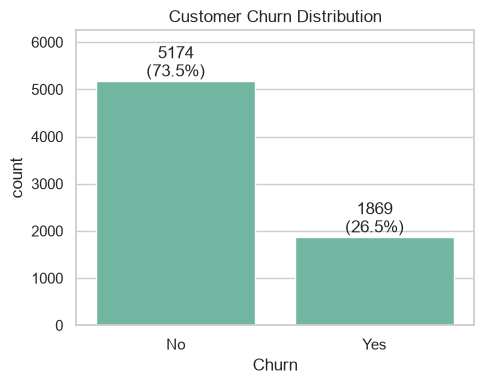

In [11]:
# 4.1 Countplot - Churn
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=readable, x="Churn", order=["No", "Yes"])
for p in ax.patches:
    pct = p.get_height() / len(readable) * 100
    ax.annotate(f"{int(p.get_height())}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Customer Churn Distribution")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
savefig("01_churn_countplot.png")

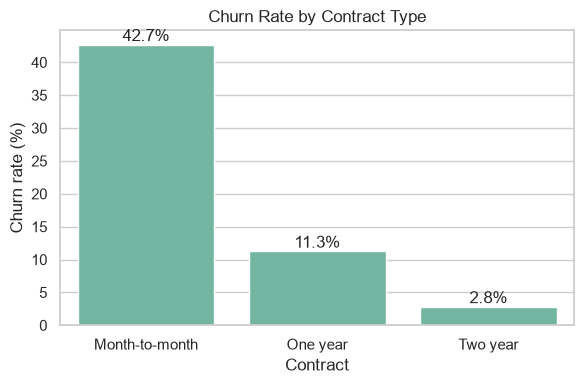

In [12]:
# 4.2 Barplot - Contract vs Churn (churn rate, %)
rate = readable.groupby("Contract")["ChurnFlag"].mean().mul(100).reset_index()
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=rate, x="Contract", y="ChurnFlag", order=["Month-to-month", "One year", "Two year"])
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn Rate by Contract Type")
savefig("02_contract_vs_churn.png")

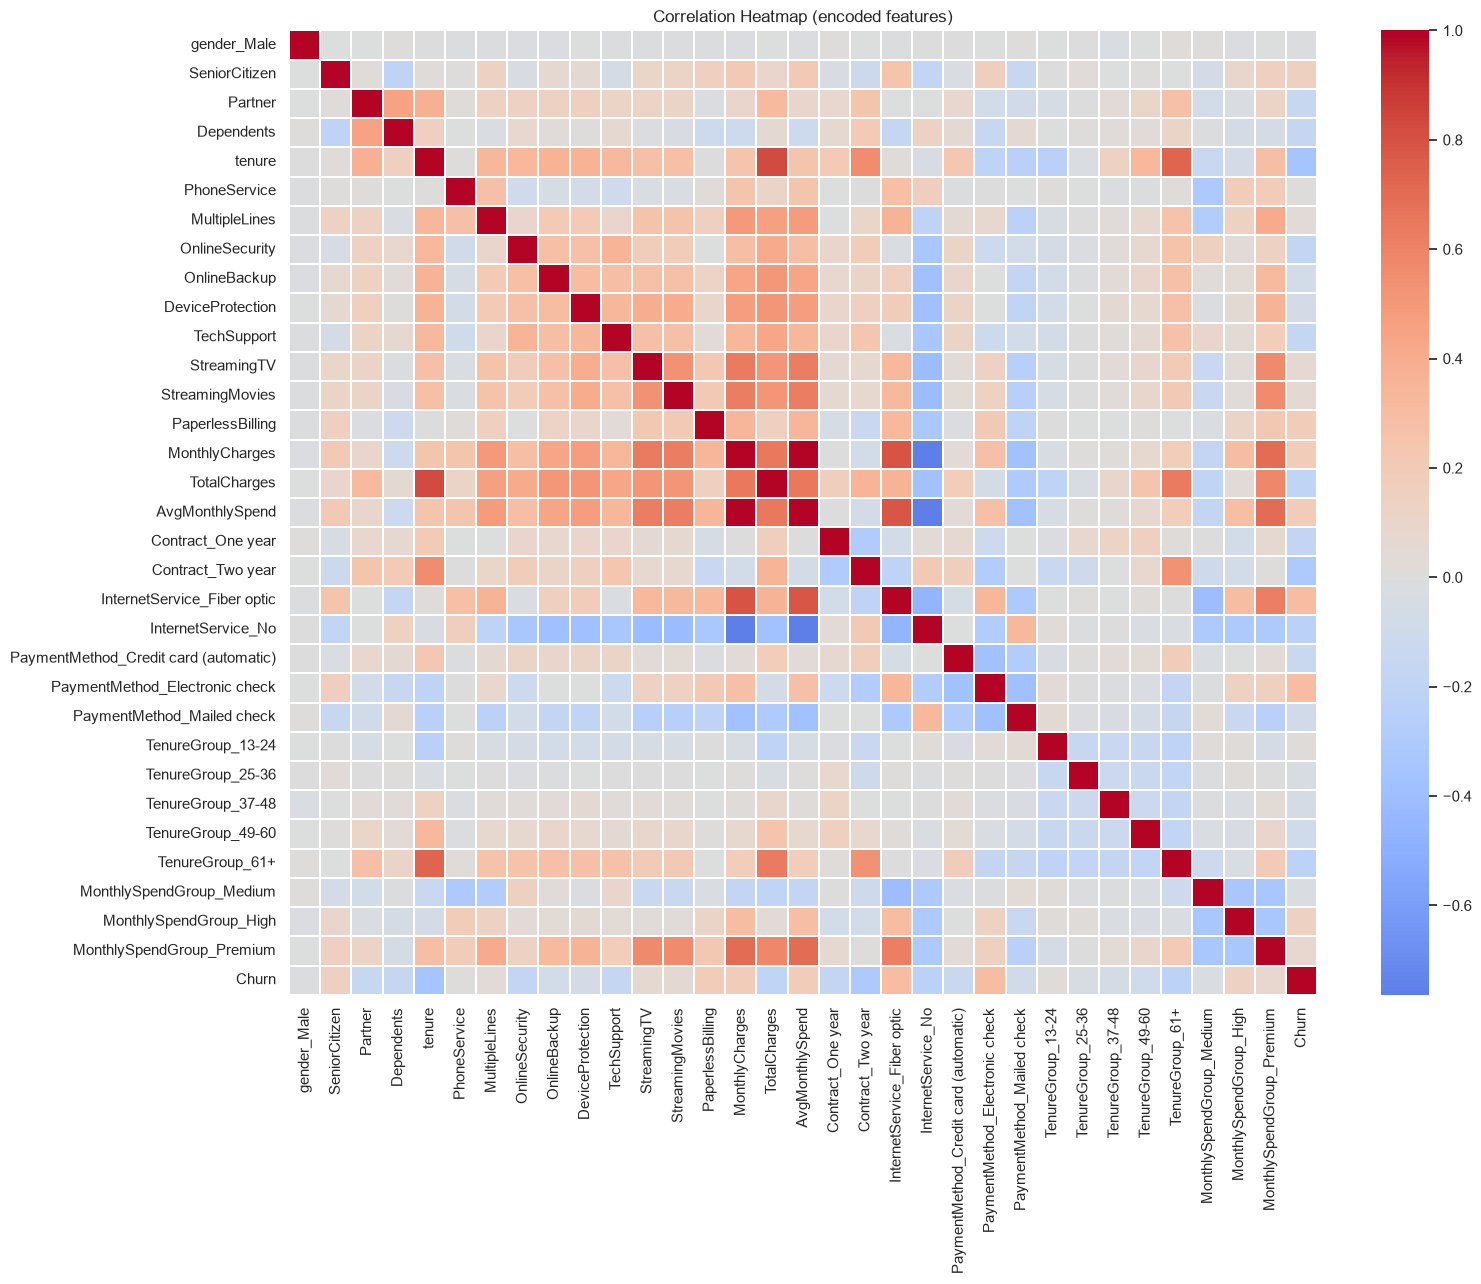

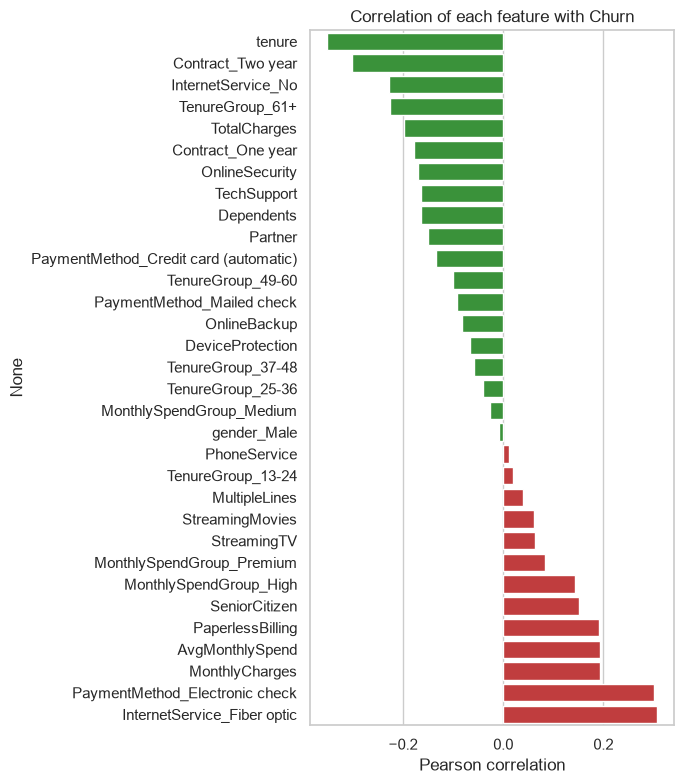

In [13]:
# 4.3 Heatmap - correlations (all numeric/encoded features)
corr = enc.drop(columns=["customerID", "Churn"]).assign(Churn=enc["Churn"]).corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=.3, annot=False)
plt.title("Correlation Heatmap (encoded features)")
savefig("03_correlation_heatmap.png")

# Focused view: what correlates most with Churn?
top = corr["Churn"].drop("Churn").sort_values()
plt.figure(figsize=(7, 8))
sns.barplot(x=top.values, y=top.index, palette=["#d62728" if v > 0 else "#2ca02c" for v in top.values])
plt.title("Correlation of each feature with Churn")
plt.xlabel("Pearson correlation")
savefig("03b_churn_correlations.png")

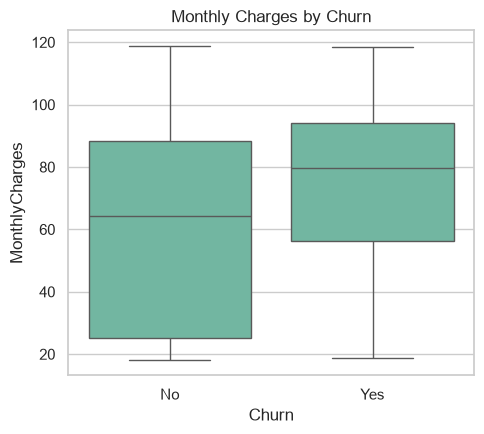

In [14]:
# 4.4 Boxplot - MonthlyCharges by Churn
plt.figure(figsize=(5, 4.5))
sns.boxplot(data=readable, x="Churn", y="MonthlyCharges", order=["No", "Yes"])
plt.title("Monthly Charges by Churn")
savefig("04_monthlycharges_boxplot.png")

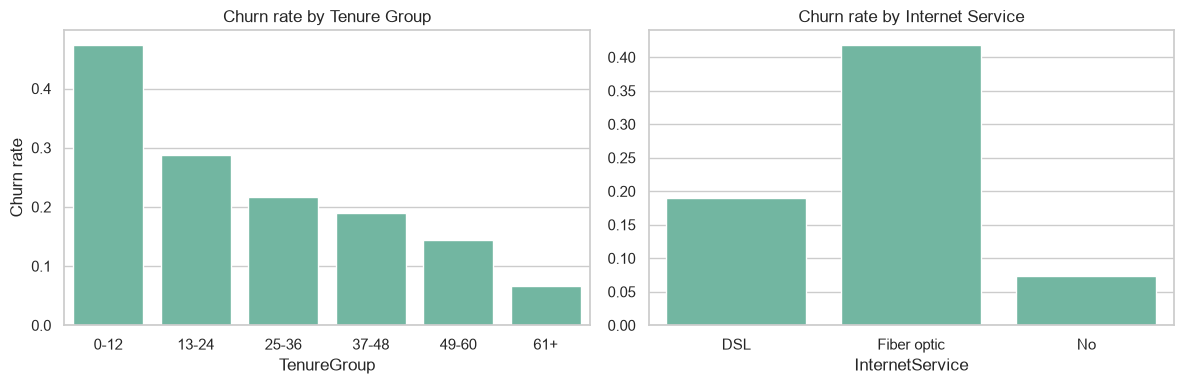

In [15]:
# 4.5 Extra: churn rate by TenureGroup and InternetService
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=readable, x="TenureGroup", y="ChurnFlag", errorbar=None, ax=axes[0])
axes[0].set_title("Churn rate by Tenure Group"); axes[0].set_ylabel("Churn rate")
sns.barplot(data=readable, x="InternetService", y="ChurnFlag", errorbar=None, ax=axes[1])
axes[1].set_title("Churn rate by Internet Service"); axes[1].set_ylabel("")
savefig("05_tenure_internet_churn.png")

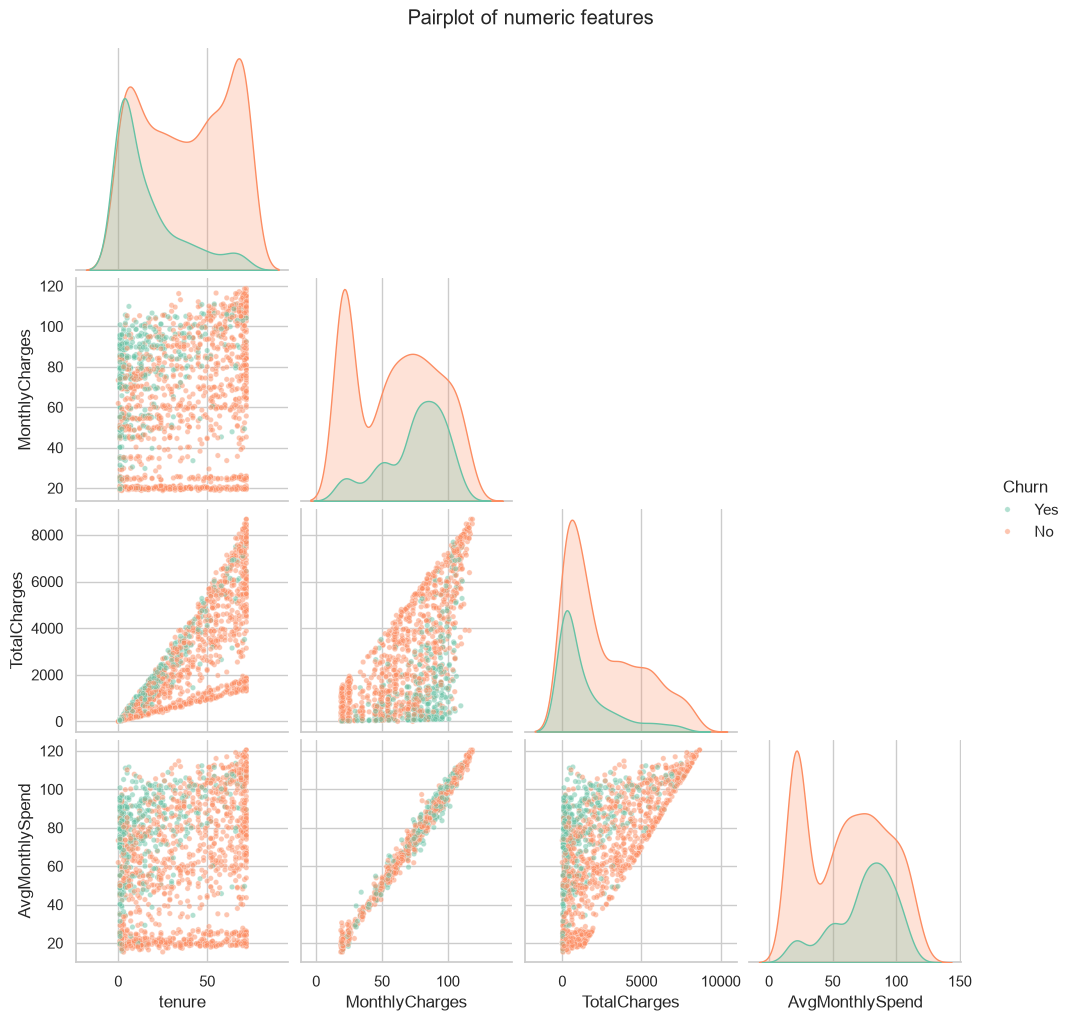

In [16]:
# 4.6 Pairplot of the numeric features
sample = readable.sample(min(1500, len(readable)), random_state=42)
g = sns.pairplot(sample, vars=["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlySpend"],
                 hue="Churn", corner=True, plot_kws={"alpha": .5, "s": 15})
g.fig.suptitle("Pairplot of numeric features", y=1.02)
g.savefig(FIG / "06_pairplot.png", dpi=120)
plt.show()

## 5. Summarize the main findings

The comparisons below highlight groups with different churn rates. They’re useful signals to follow up on—not proof that any single factor causes churn.

In [17]:
overall = readable["ChurnFlag"].mean() * 100
by_contract = readable.groupby("Contract")["ChurnFlag"].mean() * 100
by_tenure = readable.groupby("TenureGroup")["ChurnFlag"].mean() * 100
med = readable.groupby("Churn")["MonthlyCharges"].median()
by_internet = readable.groupby("InternetService")["ChurnFlag"].mean() * 100
by_pay = readable.groupby("PaymentMethod")["ChurnFlag"].mean() * 100
top_pos = corr["Churn"].drop("Churn").sort_values(ascending=False).head(3)

insights = [
    f"About one in four customers left: churn is {overall:.1f}%, so the dataset has many more retained than churned customers. For a model, account for that imbalance and look beyond accuracy alone—for example, at recall, F1, and AUC.",
    f"Churn rates vary by contract: {by_contract['Month-to-month']:.1f}% for month-to-month customers, {by_contract['One year']:.1f}% for one-year contracts, and {by_contract['Two year']:.1f}% for two-year contracts. This is a useful pattern to investigate, but it does not show that longer contracts would reduce churn.",
    f"The first year stands out: churn is {by_tenure['0-12']:.1f}% for customers with 0–12 months of tenure, compared with {by_tenure['61+']:.1f}% for those with 61 months or more. It may be worth looking more closely at the early customer experience.",
    f"Customers who left had a median monthly charge of {med.get('Yes', float('nan')):.2f}, compared with {med.get('No', float('nan')):.2f} for those who stayed. This difference merits a closer look, but does not show that price caused customers to leave.",
    f"Churn rates also differ across service and payment groups: {by_internet.idxmax()} has the highest service-group rate ({by_internet.max():.1f}%), and {by_pay.idxmax()} has the highest payment-group rate ({by_pay.max():.1f}%). The strongest positive correlations are " + ", ".join(f"{k} ({v:+.2f})" for k, v in top_pos.items()) + ". These are associations, not causal effects.",
]
for i, t in enumerate(insights, 1):
    print(f"{i}. {t}\n")

1. About one in four customers left: churn is 26.5%, so the dataset has many more retained than churned customers. For a model, account for that imbalance and look beyond accuracy alone—for example, at recall, F1, and AUC.

2. Churn rates vary by contract: 42.7% for month-to-month customers, 11.3% for one-year contracts, and 2.8% for two-year contracts. This is a useful pattern to investigate, but it does not show that longer contracts would reduce churn.

3. The first year stands out: churn is 47.4% for customers with 0–12 months of tenure, compared with 6.6% for those with 61 months or more. It may be worth looking more closely at the early customer experience.

4. Monthly charges are higher among customers who left. Their median is 79.65, compared with 64.43 for customers who stayed. That difference is a useful prompt for further analysis, but it does not by itself show that price caused customers to leave.

5. Rates also differ across service and payment groups. Fiber optic custome

## 6. Save the results

In [18]:
enc.to_csv(OUT / "churn_cleaned.csv", index=False)               # model-ready (encoded)
readable.to_csv(OUT / "churn_cleaned_readable.csv", index=False)  # human-readable
with open("insights_summary.md", "w", encoding="utf-8") as f:
    f.write("# Task 3 — Customer churn: five takeaways\n\n")
    f.write("These are patterns in the dataset, not proof that any one factor causes a customer to leave. They can help point to questions worth exploring next.\n\n")
    for i, t in enumerate(insights, 1):
        f.write(f"{i}. {t}\n\n")
print("Saved:", OUT / "churn_cleaned.csv", "|", OUT / "churn_cleaned_readable.csv", "| insights_summary.md")

Saved: ..\data\processed\churn_cleaned.csv | ..\data\processed\churn_cleaned_readable.csv | insights_summary.md
